# Market-Risk VaR Engine — Day 5
## Consolidated Risk Report + Test Suite

Days 1-4 built the components: P&L, VaR (3 methods), Expected Shortfall,
backtesting, and PLAT. Today we do the two things that turn a set of notebooks
into a real, trustworthy engine:

1. A **single consolidated report** — one call that runs the whole battery and
   produces clean output a risk manager can read.
2. **Tests** — checks that the risk functions behave correctly. A market-risk
   model that isn't tested is a liability; "model testing" is a named
   responsibility of the role, and most portfolio projects skip it entirely.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Rebuild the engine (Days 1-4, condensed)

All the functions from the previous days, gathered in one place so this
notebook is self-contained.


In [2]:
PORTFOLIO = {
    "AAPL": (1_000_000, +1),
    "JPM": (750_000, +1),
    "SPY": (2_000_000, -1),
    "FXE": (1_500_000, +1),
    "FXY": (1_000_000, -1),
    "TLT": (1_250_000, +1),
}
START_DATE, END_DATE = "2019-01-01", "2024-12-31"


def signed_notionals():
    return pd.Series({t: n * d for t, (n, d) in PORTFOLIO.items()})


def make_synthetic_prices():
    dates = pd.bdate_range(START_DATE, END_DATE)
    n = len(dates)
    ann_vol = {
        "AAPL": 0.30,
        "JPM": 0.28,
        "SPY": 0.18,
        "FXE": 0.08,
        "FXY": 0.10,
        "TLT": 0.13,
    }
    beta = {"AAPL": 1.1, "JPM": 1.0, "SPY": 1.0, "FXE": 0.1, "FXY": -0.1, "TLT": -0.3}
    market = np.random.normal(0, 0.01, n)
    rets = {
        t: beta[t] * market + np.random.normal(0, ann_vol[t] / np.sqrt(252), n)
        for t in PORTFOLIO
    }
    return 100 * np.exp(pd.DataFrame(rets, index=dates).cumsum())


def historical_var(pnl, c=0.99):
    return -np.quantile(pnl, 1 - c)


def parametric_var(pnl, c=0.99):
    return -(pnl.mean() + stats.norm.ppf(1 - c) * pnl.std())


def monte_carlo_var(returns, w, c=0.99, n_sims=100_000, seed=42):
    rng = np.random.default_rng(seed)
    sims = rng.multivariate_normal(
        returns[w.index].mean().values, returns[w.index].cov().values, size=n_sims
    )
    return -np.quantile(sims @ w.values, 1 - c)


def historical_es(pnl, c=0.99):
    thr = np.quantile(pnl, 1 - c)
    return -pnl[pnl <= thr].mean()


def rolling_backtest(pnl, c=0.99, window=250, method="historical"):
    alpha = 1 - c
    z = stats.norm.ppf(alpha)
    rec = []
    v = pnl.values
    for t in range(window, len(pnl)):
        win = v[t - window : t]
        var = (
            -np.quantile(win, alpha)
            if method == "historical"
            else -(win.mean() + z * win.std())
        )
        rec.append(
            {"date": pnl.index[t], "VaR": var, "pnl": v[t], "exception": v[t] < -var}
        )
    return pd.DataFrame(rec).set_index("date")


def basel_traffic_light(n_exc, n_days, c=0.99):
    scaled = n_exc * (250 / n_days)
    z = "GREEN" if scaled < 5 else ("AMBER" if scaled < 10 else "RED")
    return z, scaled


def kupiec_pof_test(n_exc, n_days, c=0.99):
    p = 1 - c
    x = n_exc
    n = n_days
    ph = x / n
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        lr = -2 * (
            (n - x) * np.log(1 - p)
            + x * np.log(p)
            - (n - x) * np.log(1 - ph)
            - x * np.log(ph)
        )
    return lr, 1 - stats.chi2.cdf(lr, df=1)


def hypothetical_pnl(returns, w):
    return pd.Series(returns[w.index].values @ w.values, index=returns.index)


def risk_theoretical_pnl(returns, w, omit=None, factor_scale=None, noise=0.0, seed=0):
    used = w.copy()
    if omit:
        used = used.drop(omit)
    if factor_scale:
        for t, s in factor_scale.items():
            if t in used.index:
                used[t] = used[t] * s
    base = returns[used.index].values @ used.values
    if noise:
        base = base + np.random.default_rng(seed).normal(
            0, noise * base.std(), len(base)
        )
    return pd.Series(base, index=returns.index)


def plat_metrics(hpl, rtpl):
    return stats.spearmanr(hpl, rtpl)[0], stats.ks_2samp(hpl, rtpl)[0]


def plat_zone(sp, ks):
    if sp >= 0.80 and ks <= 0.09:
        return "GREEN (pass)"
    if sp < 0.70 or ks > 0.12:
        return "RED (fail)"
    return "AMBER (watch)"


try:
    import yfinance as yf

    raw = yf.download(
        list(PORTFOLIO),
        start=START_DATE,
        end=END_DATE,
        auto_adjust=True,
        progress=False,
    )["Close"]
    prices = raw[list(PORTFOLIO)].dropna()
    if prices.empty:
        raise RuntimeError("empty")
    SOURCE = "real (Yahoo Finance)"
except Exception as e:
    prices = make_synthetic_prices()
    SOURCE = f"synthetic ({type(e).__name__})"

returns = np.log(prices / prices.shift(1)).dropna()
w = signed_notionals()
pnl = pd.Series(returns[w.index].values @ w.values, index=returns.index, name="pnl")
print(f"Engine loaded. Source: {SOURCE}  |  {len(pnl):,} days")

Engine loaded. Source: real (Yahoo Finance)  |  1,508 days


## 1. The consolidated risk report

One function that runs the full battery — VaR (3 methods), ES, backtesting
(Basel + Kupiec), and PLAT — and returns a clean, structured summary. This is
the engine's single entry point.


In [3]:
def run_full_risk_report(pnl, returns, w, confidence=0.99, window=250):
    """Run the complete risk battery and return a structured report dict."""

    var_hist = historical_var(pnl, confidence)
    var_para = parametric_var(pnl, confidence)
    var_mc = monte_carlo_var(returns, w, confidence)
    es = historical_es(pnl, confidence)

    bt = rolling_backtest(pnl, confidence, window, "historical")
    n_days = len(bt)
    n_exc = int(bt["exception"].sum())
    zone, scaled = basel_traffic_light(n_exc, n_days, confidence)
    lr, kupiec_p = kupiec_pof_test(n_exc, n_days, confidence)

    hpl = hypothetical_pnl(returns, w)
    rtpl_good = risk_theoretical_pnl(returns, w, noise=0.02)
    rtpl_poor = risk_theoretical_pnl(
        returns, w, omit=["SPY"], factor_scale={"AAPL": 0.5, "JPM": 0.5}, noise=0.05
    )
    sp_g, ks_g = plat_metrics(hpl, rtpl_good)
    sp_p, ks_p = plat_metrics(hpl, rtpl_poor)

    return {
        "confidence": confidence,
        "VaR": {"historical": var_hist, "parametric": var_para, "monte_carlo": var_mc},
        "ES": es,
        "ES_VaR_ratio": es / var_hist,
        "backtest": {
            "days": n_days,
            "exceptions": n_exc,
            "expected": (1 - confidence) * n_days,
            "rate": n_exc / n_days,
            "basel_zone": zone,
            "kupiec_p": kupiec_p,
        },
        "plat": {
            "good": (sp_g, ks_g, plat_zone(sp_g, ks_g)),
            "poor": (sp_p, ks_p, plat_zone(sp_p, ks_p)),
        },
    }


report = run_full_risk_report(pnl, returns, w, 0.99)

/home/vaibhav/github-cleanup/.venv-risk/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  outputs = ufunc(*args, out=...)


In [4]:
def print_report(r):
    c = r["confidence"]
    print("=" * 56)
    print(f"  MARKET-RISK REPORT  ({c:.0%} confidence, 1-day horizon)")
    print("=" * 56)
    print("\n  Value at Risk (USD):")
    for k, v in r["VaR"].items():
        print(f"    {k:<12}: {v:>12,.0f}")
    print(
        f"\n  Expected Shortfall: {r['ES']:>12,.0f}   (ES/VaR {r['ES_VaR_ratio']:.2f})"
    )
    b = r["backtest"]
    print("\n  Backtest:")
    print(
        f"    exceptions   : {b['exceptions']} of {b['days']:,} days "
        f"(expected {b['expected']:.0f})"
    )
    print(f"    observed rate: {b['rate']:.3%}  (target {1 - c:.1%})")
    print(f"    Basel zone   : {b['basel_zone']}")
    print(
        f"    Kupiec p-val : {b['kupiec_p']:.3f}  "
        f"({'reject' if b['kupiec_p'] < 0.05 else 'not rejected'})"
    )
    p = r["plat"]
    print("\n  PLAT:")
    print(
        f"    good model   : Spearman {p['good'][0]:.3f}, KS {p['good'][1]:.3f} -> {p['good'][2]}"
    )
    print(
        f"    poor model   : Spearman {p['poor'][0]:.3f}, KS {p['poor'][1]:.3f} -> {p['poor'][2]}"
    )
    print("=" * 56)


print_report(report)

  MARKET-RISK REPORT  (99% confidence, 1-day horizon)

  Value at Risk (USD):
    historical  :       42,438
    parametric  :       41,017
    monte_carlo :       41,130

  Expected Shortfall:       56,988   (ES/VaR 1.34)

  Backtest:
    exceptions   : 22 of 1,258 days (expected 13)
    observed rate: 1.749%  (target 1.0%)
    Basel zone   : GREEN
    Kupiec p-val : 0.016  (reject)

  PLAT:
    good model   : Spearman 1.000, KS 0.006 -> GREEN (pass)
    poor model   : Spearman 0.736, KS 0.034 -> AMBER (watch)


## 2. The test suite

These are the checks a model-validation team would write. They verify
**invariants** (properties that must always hold) and **analytic benchmarks**
(cases where we know the exact answer). We run them inline here; the same tests
live in `tests/test_risk.py` for pytest.


In [5]:
def test_parametric_var_matches_analytic():
    """For normal P&L, parametric 99% VaR = -(mu + z*sigma) exactly."""
    rng = np.random.default_rng(0)
    p = pd.Series(rng.normal(100, 1000, 500_000))
    expected = -(p.mean() + stats.norm.ppf(0.01) * p.std())
    assert abs(parametric_var(p, 0.99) - expected) < 1e-6


def test_es_geq_var():
    """Expected Shortfall is always >= VaR (tail average worse than threshold)."""
    rng = np.random.default_rng(1)
    p = pd.Series(rng.normal(0, 1000, 100_000))
    assert historical_es(p, 0.99) >= historical_var(p, 0.99)


def test_var_increases_with_confidence():
    """99% VaR >= 95% VaR (higher confidence => larger loss threshold)."""
    rng = np.random.default_rng(2)
    p = pd.Series(rng.normal(0, 1000, 100_000))
    assert historical_var(p, 0.99) >= historical_var(p, 0.95)


def test_historical_parametric_converge_for_normal():
    """For genuinely normal data, the two VaR methods should nearly agree."""
    rng = np.random.default_rng(3)
    p = pd.Series(rng.normal(0, 1000, 500_000))
    h, q = historical_var(p, 0.99), parametric_var(p, 0.99)
    assert abs(h - q) / q < 0.05


def test_backtest_exception_rate_is_calibrated():
    """A backtest of well-calibrated VaR yields ~ the expected exception rate."""
    rng = np.random.default_rng(4)
    p = pd.Series(rng.normal(0, 1000, 3000))
    bt = rolling_backtest(p, 0.99, 250, "parametric")
    rate = bt["exception"].mean()
    assert 0.005 < rate < 0.02


def test_kupiec_passes_for_correct_model():
    """Kupiec should NOT reject when the exception count matches expectation."""
    lr, pval = kupiec_pof_test(25, 2500, 0.99)
    assert pval > 0.05


def test_plat_detects_broken_model():
    """PLAT must flag a model missing a material factor as worse than a good one."""
    rng = np.random.default_rng(5)
    rr = pd.DataFrame(
        rng.normal(0, 0.01, (2000, len(PORTFOLIO))), columns=list(PORTFOLIO)
    )
    hpl = hypothetical_pnl(rr, w)
    good = risk_theoretical_pnl(rr, w, noise=0.02)
    poor = risk_theoretical_pnl(
        rr, w, omit=["SPY"], factor_scale={"AAPL": 0.5, "JPM": 0.5}, noise=0.05
    )
    sp_g, ks_g = plat_metrics(hpl, good)
    sp_p, ks_p = plat_metrics(hpl, poor)
    assert sp_g > sp_p and ks_g < ks_p


tests = [v for k, v in list(globals().items()) if k.startswith("test_")]
passed = 0
for t in tests:
    try:
        t()
        passed += 1
        print(f"  PASS  {t.__name__}")
    except AssertionError:
        print(f"  FAIL  {t.__name__}")
print(f"\n{passed}/{len(tests)} tests passed")

  PASS  test_parametric_var_matches_analytic
  PASS  test_es_geq_var
  PASS  test_var_increases_with_confidence
  PASS  test_historical_parametric_converge_for_normal
  PASS  test_backtest_exception_rate_is_calibrated
  PASS  test_kupiec_passes_for_correct_model
  PASS  test_plat_detects_broken_model

7/7 tests passed


Every test passing demonstrates the engine behaves correctly on cases where
the right answer is known or constrained by theory. This is the difference
between "code that runs" and "a model you can put in front of a regulator."


## 3. One-page summary figure

A single dashboard: the P&L distribution with VaR/ES marked, and the backtest
with exceptions. The kind of chart that goes at the top of a risk report.


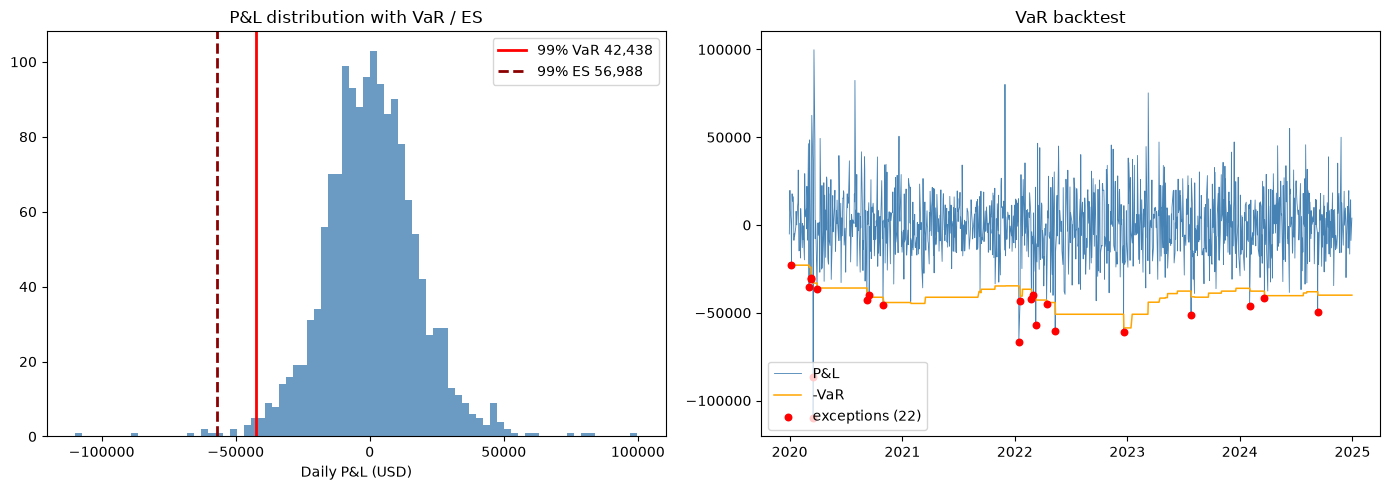

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


v = historical_var(pnl, 0.99)
es = historical_es(pnl, 0.99)
ax1.hist(pnl, bins=80, color="steelblue", alpha=0.8)
ax1.axvline(-v, color="red", lw=2, label=f"99% VaR {v:,.0f}")
ax1.axvline(-es, color="darkred", lw=2, ls="--", label=f"99% ES {es:,.0f}")
ax1.set_title("P&L distribution with VaR / ES")
ax1.set_xlabel("Daily P&L (USD)")
ax1.legend()


bt = rolling_backtest(pnl, 0.99, 250, "historical")
exc = bt[bt["exception"]]
ax2.plot(bt.index, bt["pnl"], color="steelblue", lw=0.6, label="P&L")
ax2.plot(bt.index, -bt["VaR"], color="orange", lw=1.1, label="-VaR")
ax2.scatter(
    exc.index, exc["pnl"], color="red", s=22, zorder=5, label=f"exceptions ({len(exc)})"
)
ax2.set_title("VaR backtest")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()

## Day 5 summary

The engine is now an integrated, tested system:

1. **`run_full_risk_report()`** — one call runs VaR, ES, backtesting, and PLAT
   and returns a clean structured report.
2. **A test suite** — invariants (ES >= VaR, VaR rises with confidence) and
   analytic benchmarks (parametric VaR matches the closed form), the checks a
   model-validation team writes.
3. **A one-page dashboard** figure.

**Day 6:** the **model documentation** — writing the methodology, assumptions,
limitations, and test results to a near-regulatory standard. That document is
what turns this from strong code into something that reads like real risk work.
